# 07 - Modelo principal: CNN 1D + BiGRU + CTC

**Responsable:** Leonardo Mejía

Modelo principal según la selección de la revisión bibliográfica (Avance 2). Usa la base común de
`06_preparacion_modelado` (mismos datos, mismo split por participante y mismo loop de entrenamiento),
así que sus resultados se pueden comparar directamente con los demás modelos.

In [1]:
import sys
sys.path.append("..")

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from src import dataset, features, metrics, train, vocab
from src.models import cnn_bigru

sns.set_theme(style="whitegrid")
FIGS = "../reports/figures"
train.fijar_semilla(42)

## 1. Por qué este modelo

Cada parte del modelo responde a un hallazgo del EDA o a la revisión bibliográfica:

| Hallazgo | Decisión | Fuente |
|----------|----------|--------|
| Secuencias con mediana de 147 cuadros y cola hasta ~750 | CNN 1D con *stride* que acorta la secuencia antes de la parte recurrente | Bai et al. (2018); Korotaev et al. (2025) |
| Las letras se distinguen por movimientos de pocos cuadros | Filtros de 5 cuadros sobre el eje del tiempo | LeCun et al. (1998) |
| Coarticulación entre letras y letras parecidas (M, N, T) | GRU **bidireccional**: cada letra se decide con contexto de antes y después; la tarea es *offline* | Schuster y Paliwal (1997); Graves y Schmidhuber (2005) |
| Solo 1,315 secuencias de entrenamiento y cómputo en CPU | GRU en vez de LSTM: rendimiento comparable con menos parámetros | Cho et al. (2014); Chung et al. (2014) |
| La etiqueta es la frase completa, sin alineación cuadro-letra | Pérdida CTC | Graves et al. (2006) |
| Mano derecha ausente en ~54.5 % de los cuadros | Máscara de detección como entrada (ya incluida en las 227 features) | Avance 1 |

La misma estructura (extractor convolucional + BiGRU + CTC) es la de HandReader, que con *landmarks* logró
69.3 % de exactitud por letra en ChicagoFSWild (Korotaev et al., 2025).

## 2. Arquitectura

```
x (B, T, 227) ─► Conv1d k=5, stride s ─► Conv1d k=3 ─► BiGRU (2 capas) ─► Linear ─► log_softmax (B, T/s, 60)
```

Cada bloque convolucional lleva BatchNorm, GELU y Dropout. La BiGRU recibe las secuencias empaquetadas
(`pack_padded_sequence`) para que la dirección hacia atrás no lea el relleno de las secuencias cortas.

In [2]:
loaders = dataset.crear_dataloaders(batch_size=32, max_frames=384)
x, x_len, y, y_len = next(iter(loaders["val"]))

modelo = cnn_bigru.construir()
log_probs, out_len = modelo(x, x_len)
print(modelo)
print()
print("entrada:", tuple(x.shape), "-> salida:", tuple(log_probs.shape))
print("largos de entrada:", x_len[:6].tolist())
print("largos de salida: ", out_len[:6].tolist())
print("parametros:", f"{train.n_parametros(modelo):,}")

CNNBiGRU(
  (convs): ModuleList(
    (0): BloqueConv(
      (conv): Conv1d(227, 192, kernel_size=(5,), stride=(2,), padding=(2,))
      (norm): BatchNorm1d(192, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act): GELU(approximate='none')
      (drop): Dropout(p=0.3, inplace=False)
    )
    (1): BloqueConv(
      (conv): Conv1d(192, 192, kernel_size=(3,), stride=(1,), padding=(1,))
      (norm): BatchNorm1d(192, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act): GELU(approximate='none')
      (drop): Dropout(p=0.3, inplace=False)
    )
  )
  (gru): GRU(192, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (drop): Dropout(p=0.3, inplace=False)
  (salida): Linear(in_features=256, out_features=60, bias=True)
)

entrada: (32, 384, 227) -> salida: (32, 192, 60)
largos de entrada: [127, 343, 91, 173, 70, 167]
largos de salida:  [64, 172, 46, 87, 35, 84]
parametros: 888,828


## 3. ¿Cuánto se puede reducir el tiempo?

CTC solo puede alinear si la salida tiene al menos tantos cuadros como letras tiene la frase (más uno por
cada letra repetida seguida, como la doble *l* de *hello*). Se revisa en los datos de entrenamiento qué
*stride* cumple esa condición.

In [2]:
cache = dataset.cargar_cache()
idx_train = dataset.indices_de(cache, "train")
largos = np.minimum(np.diff(cache["offsets"])[idx_train], 384)
frases = cache["phrase"][idx_train]
minimo_ctc = np.array([len(f) + sum(a == b for a, b in zip(f, f[1:])) for f in frases])

filas = []
for stride in (1, 2, 3, 4, 6):
    salida = (largos - 1) // stride + 1
    filas.append({"stride": stride, "cuadros_mediana": int(np.median(salida)),
                  "pct_secuencias_alineables": round(100 * (salida >= minimo_ctc).mean(), 1)})
pd.DataFrame(filas)

,stride,cuadros_mediana,pct_secuencias_alineables
0,1,148,96.4
1,2,74,95.5
2,3,50,94.4
3,4,37,92.5
4,6,25,84.1


Incluso sin reducir el tiempo (*stride* 1), 3.6 % de las secuencias son más cortas que su frase: el
deletreo fue tan rápido que no hay suficientes cuadros. Con *stride* 2 la pérdida es de apenas 0.9 puntos
(95.5 % alineables) y con *stride* 4 de 3.9 puntos (92.5 %); con 6 ya se pierde demasiado (84.1 %). Por eso
se prueban 2 y 4 en el ajuste. Las secuencias no alineables no rompen el entrenamiento porque `CTCLoss` usa
`zero_infinity=True`.

## 4. Ajuste de hiperparámetros

Se parte de una configuración base y se cambia **un hiperparámetro a la vez**, para saber qué efecto tiene
cada uno. Todas las corridas usan el mismo split, la misma semilla, AdamW con *one-cycle* y *early stopping*
por CER de validación. **Test no se usa para escoger**: solo se evalúa al final con el modelo elegido.

In [4]:
BASE = {"canales": 192, "kernel": 5, "stride": 2, "hidden": 128, "capas_gru": 2, "dropout": 0.3}
CONFIG_ENTRENAMIENTO = {"epochs": 60, "lr": 3e-3, "paciencia": 10}

VARIANTES = {
    "base": {},
    "stride_4": {"stride": 4},
    "mas_capacidad": {"canales": 256, "hidden": 192},
    "dropout_0.5": {"dropout": 0.5},
}

In [5]:
corridas, mejor = [], None
for nombre, cambio in VARIANTES.items():
    hp = {**BASE, **cambio}
    train.fijar_semilla(42)
    modelo = cnn_bigru.construir(**hp)
    print(f"--- {nombre}: {cambio or 'base'} ({train.n_parametros(modelo):,} parametros)")
    resultado = train.fit(modelo, loaders["train"], loaders["val"], CONFIG_ENTRENAMIENTO)
    corridas.append({"variante": nombre, "hiperparametros": hp, "n_parametros": train.n_parametros(modelo),
                     "mejor_cer_val": resultado["mejor_cer_val"], "epocas": resultado["epocas"],
                     "tiempo_s": resultado["tiempo_entrenamiento_s"], "historial": resultado["historial"]})
    if mejor is None or resultado["mejor_cer_val"] < mejor[2]["mejor_cer_val"]:
        mejor = (nombre, modelo, resultado, hp)

train.METRICS_DIR.mkdir(parents=True, exist_ok=True)
with open(train.METRICS_DIR / "cnn_bigru_tuning.json", "w", encoding="utf-8") as f:
    json.dump(corridas, f, ensure_ascii=False, indent=2)

--- base: base (888,828 parametros)


epoca   1 | train 7.189 | val 4.474 | CER 1.000


epoca   2 | train 3.798 | val 3.704 | CER 1.000


epoca   3 | train 3.584 | val 3.564 | CER 1.000


epoca   4 | train 3.473 | val 3.449 | CER 1.000


...

epoca  56 | train 1.847 | val 2.369 | CER 0.805


epoca  57 | train 1.851 | val 2.372 | CER 0.804


epoca  58 | train 1.843 | val 2.373 | CER 0.807


epoca  59 | train 1.846 | val 2.374 | CER 0.802


epoca  60 | train 1.849 | val 2.379 | CER 0.807


In [6]:
tabla_tuning = pd.DataFrame(corridas)[["variante", "n_parametros", "mejor_cer_val", "epocas", "tiempo_s"]]
tabla_tuning["tiempo_min"] = (tabla_tuning.pop("tiempo_s") / 60).round(1)
tabla_tuning.sort_values("mejor_cer_val").round(3)

,variante,n_parametros,mejor_cer_val,epocas,tiempo_min
2,mas_capacidad,1696060,0.552,60,47.7
1,stride_4,888828,0.554,60,14.8
0,base,888828,0.596,60,48.4
3,dropout_0.5,888828,0.797,60,33.1


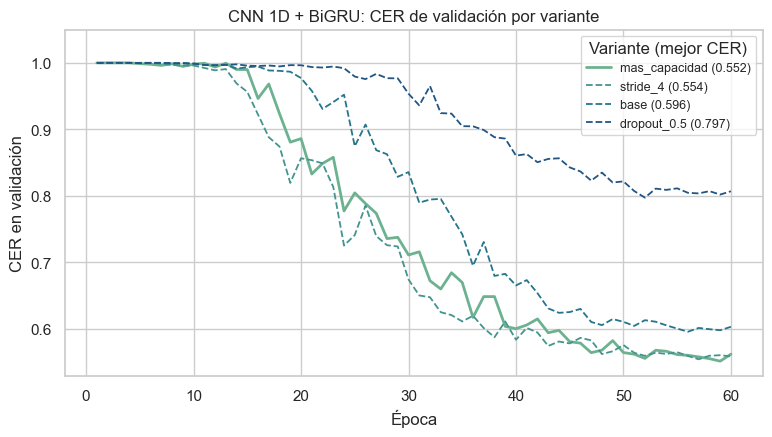

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
paleta = sns.color_palette("crest", len(corridas))
for color, c in zip(paleta, sorted(corridas, key=lambda c: c["mejor_cer_val"])):
    estilo = "-" if c["variante"] == mejor[0] else "--"
    ax.plot(range(1, len(c["historial"]["val_cer"]) + 1), c["historial"]["val_cer"], estilo,
            color=color, lw=2 if estilo == "-" else 1.3, label=f"{c['variante']} ({c['mejor_cer_val']:.3f})")
ax.set_xlabel("Época")
ax.set_ylabel("CER en validación")
ax.set_title("CNN 1D + BiGRU: CER de validación por variante")
ax.set_ylim(top=1.05)
ax.legend(title="Variante (mejor CER)", fontsize=9)
fig.savefig(f"{FIGS}/07_cnn_bigru_tuning.png", dpi=150, bbox_inches="tight")
plt.show()

**Lectura del ajuste:**

- **Más capacidad ayuda:** pasar de 192 a 256 canales y de 128 a 192 unidades en la GRU bajó el CER de
  validación de 0.596 a 0.552, con casi el doble de parámetros (1.7 M).
- **Reducir más el tiempo no perjudica:** con *stride* 4 se llegó a 0.554, prácticamente igual que la variante
  grande, en 15 minutos en vez de 48 y con la mitad de parámetros. Confirma el papel de la CNN como reductora de
  la secuencia antes de la parte recurrente.
- **Demasiado dropout frena el aprendizaje:** con 0.5 el modelo tardó mucho más en salir de la fase en que CTC
  solo predice *blanks* y terminó en 0.797.
- Ninguna variante activó el *early stopping*: las cuatro seguían mejorando en la época 60, así que con más
  épocas el CER probablemente bajaría un poco más.

Se elige **`mas_capacidad`** por tener el menor CER de validación. La variante con *stride* 4 queda como
alternativa cuando importe el tiempo de entrenamiento.

## 5. Modelo final y evaluación en test

Se guarda la mejor variante con `train.guardar_resultados`, que la evalúa en validación y en test y escribe
`models/cnn_bigru.pt` y `reports/metrics/cnn_bigru.json` (formato común que leen la app y la comparación).

In [8]:
nombre_mejor, modelo_final, resultado_final, hp_final = mejor
print("Variante elegida:", nombre_mejor, hp_final)
reporte = train.guardar_resultados("cnn_bigru", modelo_final, hp_final, resultado_final, loaders)
pd.Series({k: reporte[k] for k in ["cer_val", "cer_test", "score_kaggle_test", "n_parametros",
                                   "epocas", "tiempo_entrenamiento_s", "ms_por_secuencia"]}).round(3)

Variante elegida: mas_capacidad {'canales': 256, 'kernel': 5, 'stride': 2, 'hidden': 192, 'capas_gru': 2, 'dropout': 0.3}


cnn_bigru: CER val 0.552 | CER test 0.490 | 5.3 ms/secuencia


cer_val                         0.552
cer_test                        0.490
score_kaggle_test               0.510
n_parametros              1696060.000
epocas                         60.000
tiempo_entrenamiento_s       2859.867
ms_por_secuencia                5.340
dtype: float64

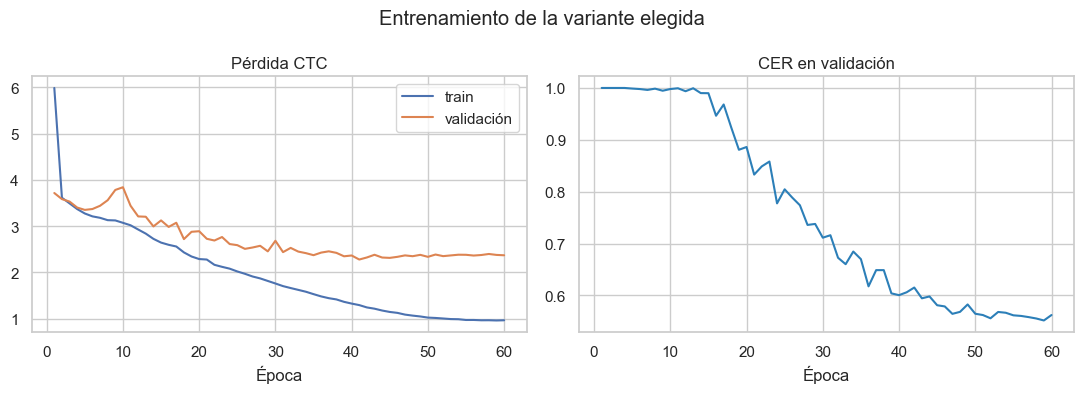

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
h = reporte["historial"]
epocas = range(1, len(h["train_loss"]) + 1)
axes[0].plot(epocas, h["train_loss"], label="train")
axes[0].plot(epocas, h["val_loss"], label="validación")
axes[0].set_title("Pérdida CTC")
axes[0].set_xlabel("Época")
axes[0].legend()
axes[1].plot(epocas, h["val_cer"], color="#2c7fb8")
axes[1].set_title("CER en validación")
axes[1].set_xlabel("Época")
fig.suptitle("Entrenamiento de la variante elegida")
fig.tight_layout()
fig.savefig(f"{FIGS}/07_cnn_bigru_entrenamiento.png", dpi=150, bbox_inches="tight")
plt.show()